In [1]:
# In this vignette we will go through the basics of convolutional neural networks using the
# example of the CIFAR100 dataset. After that, we will show three different approaches to using pre-trained networks

In [2]:
# Our installs

!pip install torchmetrics
!pip install torchinfo
!pip install pytorch_lightning
!pip install ISLP

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.6/16.6 MB 48.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 32.1 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.6/84.6 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 409.1/409.1 kB 17.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.1/287.1 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 493.0/493.0 kB 22.3 MB/s eta 0:00:00
  Created wheel for autograd-gamma: filename=autograd_gamma-0.5.0-py3-none-any.whl size=4030 sha256=cbf013bce1d2408e7467842e5fec9b205502d8e422c4149541ae91c2168f339d
  Stored in directory: /root/.cache/pip/wheels/50/37/21/0a719b9d89c635e89ff24bd93b862882ad675279552013b2fb
Successfully built autograd-gamma


In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import torch
import torchvision
from torch import nn # This is the neural network
from torch.optim import Adam # This is the optimizer I recommend
from torch.utils.data import TensorDataset
from pytorch_lightning.callbacks import Callback # This is useful for printing stuff while training
import pytorch_lightning as pl


from torchinfo import summary
from torchvision import transforms, datasets
from pytorch_lightning import Trainer
from pytorch_lightning.loggers import CSVLogger
from pytorch_lightning.callbacks import TQDMProgressBar, ModelCheckpoint, EarlyStopping

from pytorch_lightning import seed_everything
seed_everything(0,workers=True)
from torch.utils.data import DataLoader, random_split

# This makes things slightly slower but actually reprodicble
torch.use_deterministic_algorithms(True, warn_only=True)

from torchvision.datasets import CIFAR100

# ISLP helper libraries, these let you skip writing data loaders or training modules/loops
# if you so choose
from ISLP.torch import (SimpleDataModule, SimpleModule, ErrorTracker, rec_num_workers)

import os
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix


Seed set to 0


In [4]:
# One useful technique in neural networks for image recognition is to artifially
# enhance the dataset by applying random transformations. The idea is that an image of
# a car is still an image of a car even if the car has been rotated, translated, obscured partially,
# etc. By applying these transformations to the training set we are adapting to the inductive biases of the 

# This may take some time because it involves a download


transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(), # Creates a mirror image
    transforms.RandomCrop(32, padding=4), # This crops the image and adds padding
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2), # Randomly perturb the colors
    transforms.RandomRotation(5), # Randomly rotate the image
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465), # This is the mean and standard deviation of the CIFAR-100 dataset
                         (0.2470, 0.2435, 0.2616)), # We do this to normalize the colors
    transforms.RandomErasing(p=0.5, scale=(0.02, 0.2)) # Theis randomly erases a portion of the dataset
])



# We don't augment the test images, just do the same rescaling


transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616))
])



# Download the CIFAR-100 and apply the transformations
# /tmp/data is writable on both Databricks and Colab.

# You can choose to put these files somewhere else to avoid this download step,
# just make sure to update your paths as it is needed


cifar_train = datasets.CIFAR100(root='/tmp/data',
                                train=True,
                                download=True,
                                transform=transform_train)

cifar_test = datasets.CIFAR100(root='/tmp/data',
                               train=False,
                               download=True,
                               transform=transform_test)


100%|██████████| 169M/169M [13:48<00:00, 204kB/s] 


In [5]:
# Pull one batch of 10 training images to look at. These come from cifar_train and
# have already been augmented and normalized, which is why the colors look off when plotted.
data_loader = torch.utils.data.DataLoader(cifar_train, batch_size=10, shuffle=True)
sample = next(iter(data_loader))

imgs, lbls = sample

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.9894737..2.1264887].


image tensor: torch.Size([10, 3, 32, 32])
class labels: tensor([27, 39, 19, 53, 61, 37, 67,  8,  0,  4])


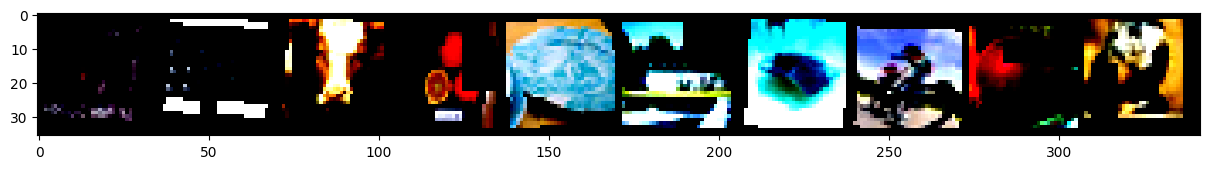

In [6]:
# create a grid
plt.figure(figsize=(15,10))
grid = torchvision.utils.make_grid(nrow=10, tensor=imgs)
print(f"image tensor: {imgs.shape}")
print(f"class labels: {lbls}")
plt.imshow(np.transpose(grid, axes=(1,2,0)), cmap='gray');

In [7]:
# ISLP wrote a nice wrapper for the pytorch lightning data modules. It randomly holds out
# 20% of the training images as a validation set, and builds
# data-loaders that hand out batches of 64 images. Only the training loader shuffles.
# The validation images are a slice of cifar_train, so they also get the random augmentations.

# This means that the estimate of accuracy based on the validation will be lower (likely)
# than the true accuracy on the training set

cifar_dm = SimpleDataModule(cifar_train,
                            cifar_test,
                            validation=0.2,
                            num_workers=0, 
                            batch_size=64) # batch size is a hyperparameter, bigger batch = more accurate gradient

# If we want to avoid this, there you have to pass a different validation set

# from torch.utils.data import random_split

# cifar_train_plain = datasets.CIFAR100(root='/tmp/data', train=True, download=True,
#                                      transform=transform_test)

# split_sizes = [40000, 10000]
# cifar_fit, _ = random_split(cifar_train, split_sizes, generator=torch.Generator().manual_seed(0))
# _, cifar_valid = random_split(cifar_train_plain, split_sizes, generator=torch.Generator().manual_seed(0))

#cifar_dm = SimpleDataModule(cifar_fit,
#                             cifar_test,
#                            validation=cifar_valid,
#                            num_workers=0,
#                            batch_size=64)


In [8]:
# Let's take a look at the size of an image

cifar_dm.setup(stage='fit')
X_, Y_ = next(iter(cifar_dm.train_dataloader()))
print(X_.shape, Y_.shape)

# We see that each image has 3 channels, one for Red, Green, and Blue respectively
# then the base image is 32x32

torch.Size([64, 3, 32, 32]) torch.Size([64])


In [9]:

# Here we are going to construct a basic CNN to perform image recognition
# This is based on the structure in the chapter 10 vignette. The building block
# class creates a "block" with some number of convolutional layers connected to a max
# pooling layer. Then these blocks are stacked together to create the final
# network


class BuildingBlock(nn.Module):

  def __init__(self,
               in_channels,
               out_channels):
    super(BuildingBlock,self).__init__()

    self.conv = nn.Conv2d(in_channels = in_channels,
                          out_channels=out_channels,
                          kernel_size=(3,3),
                          padding = 'same') # Padding = 'same' adds "0" elements
                          # at the edge of the image so that the result of applying
                          # the convolution is a feature map of the same dimension
                          # as the input

    self.bn = nn.BatchNorm2d(out_channels) # This is very helpful when training
    # as mentioned in the meetup, especially when you are stacking many convolutional
    # layers

    # We pass the convolutional feature maps through a ReLU layer which acts
    # as a "detector"
    self.activation = nn.ReLU()

    # This is the max pooling layer. It takes each of the input feature maps and breaks them
    # into square 2x2 blocks. Then it reduces each of those blocks to a single "pixel" with value
    # given by the max.

    self.pool = nn.MaxPool2d(kernel_size=(2,2))

  def forward(self,x):
    x = self.conv(x)
    x = self.bn(x) # Rescales the network output during training
    x = self.activation(x)
    x = self.pool(x)
    return x

In [10]:
# Here we define our convolutional neural network

class CIFARModel(nn.Module):

  # We are going to pass the sizes into the building block

  def __init__(self):
    super(CIFARModel,self).__init__()

    # This structure of increasing the number of filters at each step is
    # very commonly used in image recognition.

    # Initially, the image is 3x32x32. Those "3" channels each correspond
    # to a given color

    # The First layer applies 64 convolution filters.
    # The second applies 128
    # The thrd applies 256
    # The fourth applies 512

    # At each level there is a max pooling which cuts the image in half, thus
    # 4 layers is the max we can have

# So here we have 64 convolution filters. Because there are 3 input channels, each filter is 3x3x3 (a 3x3 for the space and then one for each
# color.

# In the next layer, there are 128 convolution filters, and each one is 64x3x3 (i.e. each filter looks at each filter map)

    sizes = [(3, 64),
         (64, 128),
         (128, 256),
         (256, 512)]

    # Once we have defined the sizes, we pass them to nn.Sequential

    # A point of explanation is required for the *[BuildingBlock...], what does the
    # * mean? It is a flashy bit of code that "unpacks" an array into a list of arguments.
    # So the list comprehension creates [BuildingBlock(3,64),BuildingBlock(64,128),...]
    # and the * makes it nn.Sequential(BuildingBlock(3,64),BuildingBlock(64,128),...)

    # This makes this class very flexible

    self.conv = nn.Sequential(*[BuildingBlock(in_,out_)
      for in_, out_ in sizes])


    # self.output is the "classification" part of the network
    # It takes the flattened output from all of the convolutional layers
    #, then applies a ReLU layer, then has a linear layer for the logits
    self.output = nn.Sequential(
        nn.Dropout(0.5), # This is a form of regularization
        nn.Linear(2*2*512, 512),
        nn.ReLU(),
        nn.Linear(512, 100) # This calculates the logits for each class
    )


  def forward(self, x):

      val = self.conv(x) # Run the convolutional layer
      val = torch.flatten(val, start_dim=1) # Flatten
      return self.output(val) # Then run the classification head and return the logits


In [11]:

# Now it is time to experiment with our network

# We extract a batch

X_ = next(iter(cifar_dm.train_dataloader()))[0]

# We initialize our model

cifar_model = CIFARModel()

# Notice how the model parameters increase layer by layer.

summary(cifar_model,
        input_data = X_,
        col_names=['input_size',
                   'output_size',
                   'num_params'])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
CIFARModel                               [64, 3, 32, 32]           [64, 100]                 --
├─Sequential: 1-1                        [64, 3, 32, 32]           [64, 512, 2, 2]           --
│    └─BuildingBlock: 2-1                [64, 3, 32, 32]           [64, 64, 16, 16]          --
│    │    └─Conv2d: 3-1                  [64, 3, 32, 32]           [64, 64, 32, 32]          1,792
│    │    └─BatchNorm2d: 3-2             [64, 64, 32, 32]          [64, 64, 32, 32]          128
│    │    └─ReLU: 3-3                    [64, 64, 32, 32]          [64, 64, 32, 32]          --
│    │    └─MaxPool2d: 3-4               [64, 64, 32, 32]          [64, 64, 16, 16]          --
│    └─BuildingBlock: 2-2                [64, 64, 16, 16]          [64, 128, 8, 8]           --
│    │    └─Conv2d: 3-5                  [64, 64, 16, 16]          [64, 128, 16, 16]         73,856
│    │    └─BatchNorm2d: 3-

In [12]:
# Setup our optimizer and classification module

cifar_optimizer = Adam(cifar_model.parameters(), lr=0.001, weight_decay=1e-4)

cifar_module = SimpleModule.classification(cifar_model,num_classes=100, optimizer = cifar_optimizer)
cifar_logger = CSVLogger('logs',name='CIFAR100')

In [13]:
# Print Metrics makes tracking the training a little nicer


class PrintMetrics(Callback):

    # There are other options here like on_train_start etc
    def on_validation_epoch_end(self, trainer, pl_module):
        metrics = trainer.callback_metrics
        epoch = trainer.current_epoch

        train_loss = metrics.get('train_loss')
        valid_loss = metrics.get('valid_loss')
        valid_acc = metrics.get('valid_accuracy')
        train_acc = metrics.get('train_accuracy')
        lr = trainer.optimizers[0].param_groups[0]['lr']
        # Just make sure the targets for printing have been created
        if all(m is not None for m in [train_loss, valid_acc, valid_loss, valid_acc]):
            print(f"Epoch {epoch:3d} | "
                  f"train_loss: {train_loss.item():.4f} | "
                  f"train_acc: {train_acc.item():.4f} | "
                  f"valid_loss: {valid_loss.item():.4f} | "
                  f"valid_acc: {valid_acc.item():.4f}  | "
                  f"lr: {lr:.6f}")

In [14]:
# Now we setup a "Trainer" using the lightning module that we created

# We specify the number of epochs, that we want to use the gpu, and some callbacks which let us track progress

# Note the use of the ModelCheckpoint. This keeps track of the validation loss during training, and "saves" the model
# with the lowest validation loss. In case the training goes off the rails, we will have the best weights to use

cifar_trainer = Trainer(deterministic=True,
                        max_epochs=100,
                        accelerator='gpu',
                        logger=cifar_logger,
                        callbacks=[ErrorTracker(), TQDMProgressBar(refresh_rate=1), PrintMetrics(),
                                   ModelCheckpoint(monitor='valid_loss', mode='min'),
                                    EarlyStopping(monitor='valid_loss', mode='min', patience=10)]) # Early stopping not a bad idea


Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [15]:
# Now finally we are ready to train!

cifar_trainer.fit(cifar_module,datamodule=cifar_dm)

LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ CIFARModel       │  2.7 M │ train │     0 │
│ 1 │ loss  │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 2.7 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 2.7 M                                                                                                
Total estimated model params size (MB): 10                                                                         
Modules in train mode: 28                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Sanity Checking: |          | 0/? [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


Training: |          | 0/? [00:00<?, ?it/s]

... (123 outputs left out)

Validation: |          | 0/? [00:00<?, ?it/s]

Epoch  62 | train_loss: 1.4203 | train_acc: 0.6719 | valid_loss: 1.7051 | valid_acc: 0.5429  | lr: 0.001000


Validation: |          | 0/? [00:00<?, ?it/s]

Epoch  63 | train_loss: 1.4170 | train_acc: 0.6562 | valid_loss: 1.7353 | valid_acc: 0.5364  | lr: 0.001000


In [16]:
# After the training, we might want to look for our log files
for root, dirs, files in os.walk('logs'):
    for f in files:
        print(os.path.join(root, f))

logs/CIFAR100/version_0/metrics.csv
logs/CIFAR100/version_0/checkpoints/epoch=53-step=33750.ckpt


In [17]:
metrics = pd.read_csv(f'{cifar_logger.log_dir}/metrics.csv')
epoch_metrics = metrics.groupby('epoch').first()
print(epoch_metrics[['train_loss', 'train_accuracy_epoch', 'valid_loss', 'valid_accuracy']])

       train_loss  train_accuracy_epoch  valid_loss  valid_accuracy
epoch                                                              
0        3.907667              0.093675    3.538716          0.1438
1        3.392384              0.173000    3.241048          0.1977
2        3.105947              0.225700    2.983985          0.2518
3        2.891748              0.265950    2.769274          0.2923
4        2.721050              0.298725    2.732669          0.2990
...           ...                   ...         ...             ...
59       1.427655              0.594175    1.708280          0.5420
60       1.428909              0.593700    1.689604          0.5493
61       1.420314              0.599100    1.718808          0.5353
62       1.416960              0.595075    1.705148          0.5429
63       1.408707              0.596550    1.735293          0.5364

[64 rows x 4 columns]


In [18]:
# How do we get the test set evaluation? This picks the best model

# Notice how the best test_accuracy is better than any of our validation accuracy. This is because we didn't 
# have to deal with the augmentations.

cifar_trainer.test(cifar_module, datamodule=cifar_dm, ckpt_path='best')

Restoring states from the checkpoint path at logs/CIFAR100/version_0/checkpoints/epoch=53-step=33750.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Loaded model weights from the checkpoint at logs/CIFAR100/version_0/checkpoints/epoch=53-step=33750.ckpt
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 'test_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.


Testing: |          | 0/? [00:00<?, ?it/s]

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test_accuracy       │    0.6031000018119812     │
│         test_loss         │    1.4690630435943604     │
└───────────────────────────┴───────────────────────────┘

[{'test_loss': 1.4690630435943604, 'test_accuracy': 0.6031000018119812}]

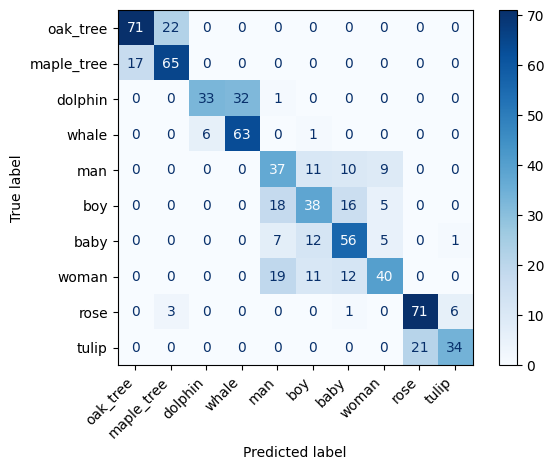

In [19]:
# Let us take a look at some bad predictions

# We need this when we are doing drop out or batch norm
cifar_module.eval()

# Thse will store the correct label, the predicted label, and the image

all_preds = []
all_labels = []
all_images = []

# Good habit to turn of backprop if we don't need it
with torch.no_grad():
    # We will extract batches from the validation set
    for x, y in cifar_dm.val_dataloader():
        logits = cifar_module(x)
        all_preds.append(torch.argmax(logits, dim=1))
        all_labels.append(y)
        all_images.append(x)


# Now we will fish out the erroneous predictions

# This is needed because the elements that were appended in the prior loop
# were for entire batches
all_preds = torch.cat(all_preds)
all_labels = torch.cat(all_labels)
all_images = torch.cat(all_images)

y_true = all_labels.numpy()
y_pred = all_preds.numpy()

class_labels = cifar_train.classes  # the 100 CIFAR-100 class names
# With 100 classes the full confusion matrix is unreadable, so we zoom in on the classes the
# model confuses most. confusion[i, j] counts mistakes between classes i and j in either
# direction; we go through the pairs from most to least confused, collecting classes until we have 10.

cm = confusion_matrix(y_true, y_pred)
confusion = cm + cm.T
np.fill_diagonal(confusion, 0)

top = []
for k in np.argsort(confusion, axis=None)[::-1]:
    for c in np.unravel_index(k, confusion.shape):
        if c not in top:
            top.append(c)
    if len(top) >= 10:
        break
top = top[:10]

# Rows don't add up to the class totals: mistakes involving classes outside these 10 are not shown
ConfusionMatrixDisplay(cm[np.ix_(top, top)],
                       display_labels=[class_labels[c] for c in top]).plot(cmap='Blues')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()


In [20]:
# Part 2: Pretrained models

# For this second part, we will begin by loading weights from models that have already
# been trained to recognize images, and adapt them for use on CIFAR-100
# These models are extremely advanced, with lots of parameters, enormous depth, and
# which have been trained on enormously large datasets.

# We will use three different techniques for using the pretrained models. THere are two
# pretrained models, DINOv2 and ResNet-50. DINOv2 is a vision transformer model, resnet 
# is a convolutional neural network

# 1. Linear probe: This does not change DINOv2 at all, but uses it to process all the images and then trains
# a classifier on the outputs. The resulting code is very simple, provides a good baselines, and is more
# like logistic regression than standard neural network training
# 2. Full fine-tuning: replace the output layer of resnet to adapt it to CIFAR-100, and
#  training the weights inside the network
# 3. LoRA: Fine-tune DINOv2 weights but constrain the perturbations to be a low rank matrix.

# We will install two more libraries (your cloud platform may already have them)
# transformers provides preretrained models from Hugging Face
# peft is useful for LoRA

!pip install transformers peft

In [21]:
from transformers import AutoModel
from peft import LoraConfig, get_peft_model
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedShuffleSplit

In [22]:
# The pretrained models were both trained on ImageNet, a much larger and higher resolution dataset than CIFAR, 
# so we normalize with ImageNet's color statistics instead of CIFAR'. The imagenet images are also 224x224, so we
# must enlarge our CIFAR images to match
# 32x32. 

imagenet_mean = (0.485, 0.456, 0.406)
imagenet_std = (0.229, 0.224, 0.225)

# We aren't applying the same augmentations anymore. This is because we already have a highly trained network we are
# just adapting the networks not trying to enhance the size of the dataset to stop overfitting

pretrained_transform_train = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

pretrained_transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

pretrained_train = datasets.CIFAR100(root='/tmp/data', train=True, download=True,
                                     transform=pretrained_transform_train)
pretrained_test = datasets.CIFAR100(root='/tmp/data', train=False, download=True,
                                    transform=pretrained_transform_test)

# The training images without augmentation, for computing the linear probe's features
pretrained_train_plain = datasets.CIFAR100(root='/tmp/data', train=True, download=True,
                                           transform=pretrained_transform_test)

pretrained_dm = SimpleDataModule(pretrained_train,
                                 pretrained_test,
                                 validation=0.2,
                                 num_workers=2,
                                 batch_size=64)


# This function scales up the images to 224x224

upsample = nn.Upsample(size=(224, 224), mode='bilinear')

In [23]:
# Option 1: Linear probe on DINOv2 features

# DINOv2 is a vision transformer trained in 2023 without labels. It cuts the image into 14x14 pixel
# patches and outputs a 768-number vector for each patch, plus one extra vector called the "CLS token"
# which acts as a summary of the whole image. The CLS token is what we use for logistic regression

# We get the weights and put them on the GPU

dino = AutoModel.from_pretrained("facebook/dinov2-base").to('cuda').eval()

# This function processes the images
def dino_features(dataset):
    loader = DataLoader(dataset, batch_size=256, num_workers=2)
    features, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            # float16 arithmetic makes this several times faster, and is accurate enough here
            with torch.autocast('cuda', dtype=torch.float16):
                output = dino(pixel_values=upsample(x.to('cuda')))
            features.append(output.last_hidden_state[:, 0].float().cpu())  # the CLS token
            labels.append(y)
    return torch.cat(features).numpy(), torch.cat(labels).numpy()

# We apply the function to obtain the features for the training and test sets
X_train_dino, y_train_dino = dino_features(pretrained_train_plain)
X_test_dino, y_test_dino = dino_features(pretrained_test)
print(X_train_dino.shape, X_test_dino.shape) # You can see that we have reduced the feature size to 768

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

(50000, 768) (10000, 768)


In [24]:
# Now we have a basic logistic regression problem. We will use sklearn and cross-validation to pick
# the best regularization strength

probe_full = make_pipeline(StandardScaler(),
                           LogisticRegressionCV(Cs=np.logspace(-4, 0, 5), cv=5, max_iter=1000))
probe_full.fit(X_train_dino, y_train_dino)


Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregressioncv',
                 LogisticRegressionCV(Cs=array([1.e-04, 1.e-03, 1.e-02, 1.e-01, 1.e+00]),
                                      cv=5, max_iter=1000))])

In [25]:
# We see how well the probe performs

probe_full_accuracy = probe_full.score(X_test_dino, y_test_dino)
print(f"best C = {probe_full[-1].C_[0]}, test accuracy {probe_full_accuracy:.4f}")

best C = 0.01, test accuracy 0.8943


In [26]:
# In your homework assignment you are going to be working with a very small dataset, with few images
# per class. So here we will examine what happens when we artificially cause the dataset to be small.
# How much labelled data does the probe need? Keep only 100 training images per class
# This will go faster

rng = np.random.default_rng(0)
small = np.concatenate([rng.choice(np.where(y_train_dino == k)[0], 100, replace=False)
                        for k in range(100)])

probe_small = make_pipeline(StandardScaler(),
                            LogisticRegressionCV(Cs=np.logspace(-4, 0, 5), cv=5, max_iter=1000))
probe_small.fit(X_train_dino[small], y_train_dino[small])
probe_small_accuracy = probe_small.score(X_test_dino, y_test_dino)
print(f"100 images per class: test accuracy {probe_small_accuracy:.4f}")

100 images per class: test accuracy 0.8727


In [27]:
# Free the GPU memory to so that we can use it for fine tuning

del dino
torch.cuda.empty_cache()

In [28]:
# Option 2: Full fine-tuning of ResNet-50

# ResNet-50 is a 50-layer CNN trained to classify ImageNet's 1000 object categories. We replace its
# final layer, which maps from 2048 features to the logits of the 1000 Imagenet classes, with a final
# layer that maps from 2048 features to the 100 classes of cifar-100. Then we train the whole network on
# cifar 100.


class ResNetCIFAR(nn.Module):

    def __init__(self):
        super(ResNetCIFAR, self).__init__()
        self.resnet = torchvision.models.resnet50(weights="IMAGENET1K_V2") # Get the weights
        self.resnet.fc = nn.Linear(2048, 100) # Replace the last layer. This is just the lingo used in the 
        # original resnet object, fc stands for fully connected

    def forward(self, x):
        # A few things are happening here. upsample is scaling up
        # the input image to the 224x224 resnet input size. Then self.resnet
        # applies the resnet network to the image.
        return self.resnet(upsample(x))

# Create an instance
resnet_model = ResNetCIFAR()

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 221MB/s]


In [29]:
# Now we are setting up the training. The main "trick" we are going to do is to give the
# output layer a alrger learning rate than the pretrained layers. This is because the output layer has not been 
# trained yet.

# We get the parameters for each layer separately

head_params = list(resnet_model.resnet.fc.parameters())
body_params = [p for name, p in resnet_model.named_parameters() if not name.startswith('resnet.fc')]

# We define the optimizer, note that we put a different learning rate for each group of parameters

resnet_optimizer = Adam([{'params': body_params, 'lr': 1e-4},
                         {'params': head_params, 'lr': 1e-3}],
                        weight_decay=1e-4)

# This is the training module

resnet_module = SimpleModule.classification(resnet_model, num_classes=100, optimizer=resnet_optimizer)

In [30]:
# Now we apply the training. We don't need that many epochs. ModelCheckpoint keeps the weights from the epoch with the
# lowest validation loss. precision='16-mixed' uses float16 arithmetic where it is supported, decreasing training time


resnet_trainer = Trainer(max_epochs=3,
                         accelerator='gpu',
                         precision='16-mixed',
                         logger=CSVLogger('logs', name='ResNet50'),
                         callbacks=[ErrorTracker(), PrintMetrics(),
                                    ModelCheckpoint(monitor='valid_loss', mode='min')])

resnet_trainer.fit(resnet_module, datamodule=pretrained_dm)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ ResNetCIFAR      │ 23.7 M │ train │     0 │
│ 1 │ loss  │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 23.7 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 23.7 M                                                                                               
Total estimated model params size (MB): 94                                                                         
Modules in train mode: 153                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

Epoch   1 | train_loss: 1.2199 | train_acc: 0.7500 | valid_loss: 0.6199 | valid_acc: 0.8137  | lr: 0.000100

Epoch   2 | train_loss: 0.4509 | train_acc: 0.9531 | valid_loss: 0.6701 | valid_acc: 0.8136  | lr: 0.000100

`Trainer.fit` stopped: `max_epochs=3` reached.


In [31]:
# ckpt_path='best' evaluates the checkpoint with the lowest validation loss, only 3 epochs

resnet_results = resnet_trainer.test(resnet_module, datamodule=pretrained_dm, ckpt_path='best')

Restoring states from the checkpoint path at logs/ResNet50/version_0/checkpoints/epoch=1-step=1250.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Loaded model weights from the checkpoint at logs/ResNet50/version_0/checkpoints/epoch=1-step=1250.ckpt


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test_accuracy       │    0.8133999705314636     │
│         test_loss         │    0.6272319555282593     │
└───────────────────────────┴───────────────────────────┘

In [32]:
# Option 3: LoRA fine-tuning of DINOv2

# LoRA is a type of fine tuning that constraints the perturbation of the weights of the network
# to be low rank. This let's us fine-tune the entire network while only making a small modification to the
# parameters, greatly speeding up the process. We also need to add an output layer to the DINOv2 network


class DinoLoRA(nn.Module):

    def __init__(self):
        super(DinoLoRA, self).__init__()
        lora_config = LoraConfig(r=8,  # rank of each update
                                 lora_alpha=16, # scale of the update
                                 lora_dropout=0.1,
                                 target_modules=['query', 'value'])  # which weight matrices to adapt
        # This line is doing a lot of work. It is loading the DINOv2 model but enabling the
        # training to occur throught the sparse weights
        self.dino = get_peft_model(AutoModel.from_pretrained("facebook/dinov2-base"), lora_config)
        self.head = nn.Linear(768, 100) # Adding the classifier head



    def forward(self, x): 
        # Get the cls token (and upsample)
        cls_token = self.dino(pixel_values=upsample(x)).last_hidden_state[:, 0]
        # Apply the classifier head
        return self.head(cls_token)

lora_model = DinoLoRA()
lora_model.dino.print_trainable_parameters()

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

trainable params: 294,912 || all params: 86,875,392 || trainable%: 0.3395


In [33]:
# We do the training. It doesn't take many epochs to adapt

lora_params = [p for p in lora_model.dino.parameters() if p.requires_grad]

# Different learning rate for the classification head
lora_optimizer = Adam([{'params': lora_params, 'lr': 2e-4},
                       {'params': lora_model.head.parameters(), 'lr': 1e-3}])

lora_module = SimpleModule.classification(lora_model, num_classes=100, optimizer=lora_optimizer)

lora_trainer = Trainer(max_epochs=2,
                       accelerator='gpu',
                       precision='16-mixed',
                       logger=CSVLogger('logs', name='DINOv2_LoRA'),
                       callbacks=[ErrorTracker(), PrintMetrics(),
                                  ModelCheckpoint(monitor='valid_loss', mode='min')])

lora_trainer.fit(lora_module, datamodule=pretrained_dm)

Trainer will use only 1 of 2 GPUs because it is running inside an interactive / notebook environment. You may try to set `Trainer(devices=2)` but please note that multi-GPU inside interactive / notebook environments is considered experimental and unstable. Your mileage may vary.
Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name  ┃ Type             ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model │ DinoLoRA         │ 87.0 M │ train │     0 │
│ 1 │ loss  │ CrossEntropyLoss │      0 │ train │     0 │
└───┴───────┴──────────────────┴────────┴───────┴───────┘

Trainable params: 371 K                                                                                            
Non-trainable params: 86.6 M                                                                                       
Total params: 87.0 M                                                                                               
Total estimated model params size (MB): 347                                                                        
Modules in train mode: 245                                                                                         
Modules in eval mode: 224                                                                                          
Total FLOPs: 0

Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/loops/fit_loop.py:534: Found 224 module(s) in eval mode 
at the start of training. This may lead to unexpected behavior during training. If this is intentional, you can 
ignore this warning.

Epoch   1 | train_loss: 0.4389 | train_acc: 0.9375 | valid_loss: 0.2732 | valid_acc: 0.9225  | lr: 0.000200

`Trainer.fit` stopped: `max_epochs=2` reached.


In [34]:
# We evaluate the lora model

lora_results = lora_trainer.test(lora_module, datamodule=pretrained_dm, ckpt_path='best')

Restoring states from the checkpoint path at logs/DINOv2_LoRA/version_0/checkpoints/epoch=0-step=625.ckpt
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]
Loaded model weights from the checkpoint at logs/DINOv2_LoRA/version_0/checkpoints/epoch=0-step=625.ckpt


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│       test_accuracy       │    0.9182999730110168     │
│         test_loss         │    0.27824801206588745    │
└───────────────────────────┴───────────────────────────┘

In [35]:
# Comparing the three approaches on the test set

pd.Series({'Linear probe, full training set': probe_full_accuracy,
           'Linear probe, 100 images per class': probe_small_accuracy,
           'ResNet-50 fine-tuned': resnet_results[0]['test_accuracy'],
           'DINOv2 LoRA': lora_results[0]['test_accuracy']},
          name='test accuracy').round(4)

Linear probe, full training set       0.8943
Linear probe, 100 images per class    0.8727
ResNet-50 fine-tuned                  0.8134
DINOv2 LoRA                           0.9183
Name: test accuracy, dtype: float64